# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [10]:
ROLL_NO = 1024170040         # <-- your full roll number
NAME = "Sanvi"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [11]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [12]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [13]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170040   Name: Sanvi   Fingerprint: C1E494E7   Tickets: 12

Ticket_ID                                                                          Ticket_Text
      T01                  I tried restarting the student portal on my laptop. This is urgent.
      T02                                       Re-installing didn't help; log-in still fails!
      T03                 Password is not working on my laptop. The same problem occurs again.
      T04                             Student portal failed to open on my laptop. Please help.
      T05                                                        Version 2.0.1 crashes at 99%.
      T06                           The Matlab stopped responding. I have tried several times!
      T07                         Server is showing an error on my laptop. Can you check this?
      T08 I reinstalled the Matlab before the assignment deadline. I have tried several times!
      T09                                                The Wi-Fi w

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [14]:

import pandas as pd

# Dictionary to store processed results
processed_data = {}

# Lists to store table information
rows = []

# Process every ticket
for index, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    result = process_ticket(text)

    processed_data[ticket_id] = result

    rows.append({
        "Ticket ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

# Creating DataFrame
result_table = pd.DataFrame(rows)

# Adding TOTAL row
total_row = {
    "Ticket ID": "TOTAL",
    "Sentences": result_table["Sentences"].sum(),
    "Tokens": result_table["Tokens"].sum(),
    "Punctuation": result_table["Punctuation"].sum(),
    "Stopwords": result_table["Stopwords"].sum(),
    "Unique Tokens": result_table["Unique Tokens"].sum(),
    "Final Tokens": result_table["Final Tokens"].sum()
}

result_table = pd.concat(
    [result_table, pd.DataFrame([total_row])],
    ignore_index=True
)

print("PREPROCESSING SUMMARY")
display(result_table)

# Selecting one focus ticket
selected_id = FOCUS[0]
selected = processed_data[selected_id]

print("\nSelected Ticket:", selected_id)
print("Actual Tokens:", selected["tokens"])
print("Punctuation Tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final Tokens:", selected["final"])


PREPROCESSING SUMMARY


,Ticket ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,14,2,6,13,6
1,T02,1,9,2,1,9,6
2,T03,2,14,2,7,13,5
3,T04,2,12,2,3,11,7
4,T05,1,7,2,1,7,4
5,T06,2,11,2,3,11,6
6,T07,2,14,2,7,14,5
7,T08,2,15,2,6,13,7
8,T09,1,10,2,4,9,4
9,T10,2,14,2,6,14,6



Selected Ticket: T02
Actual Tokens: ['re-installing', 'did', "n't", 'help', ';', 'log-in', 'still', 'fails', '!']
Punctuation Tokens: [';', '!']
Stopwords: ['did']
Final Tokens: ['re-installing', "n't", 'help', 'log-in', 'still', 'fails']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [15]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

# Combining raw tickets and test lines
all_texts = df["Ticket_Text"].tolist() + TEST_LINES

# Regex patterns
long_words_pattern = r"\b[A-Za-z]{6,}\b"

numbers_pattern = r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?![\w.])"

capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

vowel_pattern = r"\b[aeiou][a-z]*\b"

# Extracting information using findall()
for i, text in enumerate(all_texts):

    print("\nText:", text)

    print("Words longer than 5 letters:",
          re.findall(long_words_pattern, text))

    print("Numbers:",
          re.findall(numbers_pattern, text))

    print("Capitalized words:",
          re.findall(capitalized_pattern, text))

    print("Words starting with vowels:",
          re.findall(vowel_pattern, text, flags=re.IGNORECASE))


# Replacing emails, URLs and phone numbers
def clean_text(text):

    # Replace email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )

    # Replace URLs
    text = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "<URL>",
        text
    )

    # Replace phone numbers
    text = re.sub(
        r"(?<!\w)(?:\+91[-\s]?)?(?:\d{5}[-\s]?\d{5}|\d{4}-\d{3}-\d{4})(?!\w)",
        "<PHONE>",
        text
    )

    return text


print("\n\nREPLACEMENT RESULTS")

for text in TEST_LINES:
    print("\nOriginal:", text)
    print("Modified:", clean_text(text))



Text: I tried restarting the student portal on my laptop. This is urgent.
Words longer than 5 letters: ['restarting', 'student', 'portal', 'laptop', 'urgent']
Numbers: []
Capitalized words: ['I', 'This']
Words starting with vowels: ['I', 'on', 'is', 'urgent']

Text: Re-installing didn't help; log-in still fails!
Words longer than 5 letters: ['installing']
Numbers: []
Capitalized words: ['Re']
Words starting with vowels: ['installing', 'in']

Text: Password is not working on my laptop. The same problem occurs again.
Words longer than 5 letters: ['Password', 'working', 'laptop', 'problem', 'occurs']
Numbers: []
Capitalized words: ['Password', 'The']
Words starting with vowels: ['is', 'on', 'occurs', 'again']

Text: Student portal failed to open on my laptop. Please help.
Words longer than 5 letters: ['Student', 'portal', 'failed', 'laptop', 'Please']
Numbers: []
Capitalized words: ['Student', 'Please']
Words starting with vowels: ['open', 'on']

Text: Version 2.0.1 crashes at 99%.
Words

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some capitalized words are proper nouns or abbreviations, while others are capitalized simply because they occur at the beginning of a sentence. Regex cannot automatically distinguish these two cases just by checking uppercase letters.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [16]:

from nltk.tokenize import RegexpTokenizer, word_tokenize

# Creating one regex pattern for custom tokenization
pattern = r"""https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|(?<!\w)(?:\+91[-\s]?)?(?:\d{5}[-\s]?\d{5}|\d{4}-\d{3}-\d{4})(?!\w)|\d+(?:\.\d+)+|[A-Za-z]+(?:['’][A-Za-z]+)?(?:-[A-Za-z]+(?:['’][A-Za-z]+)?)*|[^\w\s]"""

# Creating tokenizer
tokenizer = RegexpTokenizer(pattern)

# Custom tokenization function
def my_tokenize(text):
    return tokenizer.tokenize(text)


# Testing on TEST_LINES
print("CUSTOM TOKENIZATION ON TEST LINES")

for text in TEST_LINES:
    print("\nOriginal:", text)
    print("Custom Tokens:", my_tokenize(text))
    print("Word Tokens:", word_tokenize(text))


# Running on generated tickets
print("\n\nCOMPARISON ON GENERATED TICKETS")

different_tickets = []

for index, row in df.iterrows():

    text = row["Ticket_Text"]

    custom = my_tokenize(text)
    normal = word_tokenize(text)

    if custom != normal:
        different_tickets.append(row["Ticket_ID"])

    print("\nTicket:", row["Ticket_ID"])
    print("Custom:", custom)
    print("Word Tokenize:", normal)

print("\nTickets with different tokenization:",
      len(different_tickets))

print("Different Ticket IDs:", different_tickets)


CUSTOM TOKENIZATION ON TEST LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom Tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Word Tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom Tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']
Word Tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't open; log-i

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The custom tokenizer uses a specifically designed regular expression to preserve contractions, hyphenated words, decimals, versions, emails, URLs and phone numbers as single tokens.

The standard word_tokenize() follows general English tokenization rules and may split these special patterns into multiple tokens.

The exact number of tickets with different tokenization is printed by the program.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [17]:

import nltk
import pandas as pd

from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# Collecting all unique final tokens
unique_final_tokens = sorted(set(
    token
    for result in processed_data.values()
    for token in result["final"]
))

# Creating stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Regexp Stemmer: removing "ing"
regexp = RegexpStemmer("ing$", min=4)

lemmatizer = WordNetLemmatizer()

# POS tag conversion function
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    else:
        return wordnet.NOUN


# Getting POS tags
pos_tags = nltk.pos_tag(unique_final_tokens)

# Creating comparison table
rows = []

for word, tag in pos_tags:

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp.stem(word)

    pos = get_wordnet_pos(tag)

    lemma_result = lemmatizer.lemmatize(word, pos)

    # Include only words where outputs differ
    if len(set([
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ])) > 1:

        rows.append({
            "Original Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "Lemmatizer": lemma_result
        })


comparison_table = pd.DataFrame(rows)

print("STEMMING AND LEMMATIZATION COMPARISON")
display(comparison_table)

# Display the suffix justification
print("\nRegexp Stemmer Rule: Removes the suffix 'ing'")
print("Examples from the dataset: restarting, working, uploading")
print("Justification: These words end with 'ing', so this suffix")
print("is selected for the Regexp Stemmer.")


STEMMING AND LEMMATIZATION COMPARISON


,Original Word,Porter,Lancaster,Regexp,Lemmatizer
0,assignment,assign,assign,assignment,assignment
1,changed,chang,chang,changed,change
2,crashes,crash,crash,crashes,crash
3,deadline,deadlin,deadlin,deadline,deadline
4,details,detail,detail,details,detail
5,error,error,er,error,error
6,failed,fail,fail,failed,fail
7,fails,fail,fail,fails,fails
8,file,file,fil,file,file
9,https,http,https,https,https



Regexp Stemmer Rule: Removes the suffix 'ing'
Examples from the dataset: restarting, working, uploading
Justification: These words end with 'ing', so this suffix
is selected for the Regexp Stemmer.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* - Over-stemming occurs when a stemming algorithm removes too much of a word and produces an incorrect root.
- Under-stemming occurs when related words are not reduced to the same root even though they have similar meanings.
The exact examples should be selected from the comparison table produced by the program.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All Tokens,141,82,0.5816
1,S2 - Without Punctuation,117,75,0.6410
2,S3 - Final Tokens,67,51,0.7612
3,S4 - Porter Stemmed,67,49,0.7313



TOP 10 WORDS IN S1
[('.', 15), ('the', 9), ('i', 5), ('on', 4), ('my', 4), ('laptop', 4), ('tried', 3), ('this', 3), ('is', 3), ("n't", 3)]

TOP 10 WORDS IN S3
[('laptop', 4), ('tried', 3), ("n't", 3), ('student', 2), ('portal', 2), ('help', 2), ('working', 2), ('matlab', 2), ('several', 2), ('times', 2)]


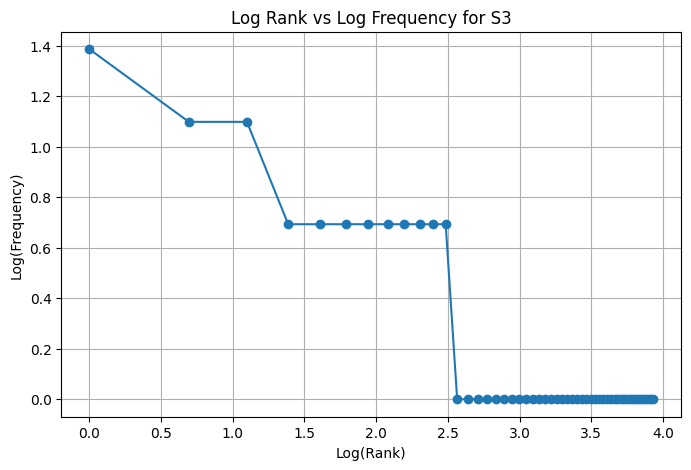


TOP 5 BIGRAMS IN S1
[(('on', 'my'), 4), (('my', 'laptop'), 4), (('laptop', '.'), 4), (('.', 'the'), 3), (('.', 'i'), 3)]

TOP 5 BIGRAMS IN S3
[(('student', 'portal'), 2), (('tried', 'several'), 2), (('several', 'times'), 2), (('tried', 'restarting'), 1), (('restarting', 'student'), 1)]


In [18]:

from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# S1: All tokens
S1 = [
    token
    for result in processed_data.values()
    for token in result["tokens"]
]

# S2: Tokens without punctuation
S2 = [
    token
    for result in processed_data.values()
    for token in result["tokens"]
    if not is_punct(token)
]

# S3: Final tokens
S3 = [
    token
    for result in processed_data.values()
    for token in result["final"]
]

# S4: S3 after Porter stemming
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]


# Function to calculate corpus statistics
def corpus_stats(tokens):

    total = len(tokens)
    unique = len(set(tokens))

    ttr = unique / total if total > 0 else 0

    return total, unique, ttr


# Creating statistics table
corpora = {
    "S1 - All Tokens": S1,
    "S2 - Without Punctuation": S2,
    "S3 - Final Tokens": S3,
    "S4 - Porter Stemmed": S4
}

rows = []

for name, tokens in corpora.items():

    total, unique, ttr = corpus_stats(tokens)

    rows.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_table = pd.DataFrame(rows)

print("CORPUS STATISTICS")
display(stats_table)


# Top 10 words
print("\nTOP 10 WORDS IN S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS IN S3")
print(Counter(S3).most_common(10))


# Log rank vs log frequency for S3
frequency = Counter(S3)

sorted_freq = frequency.most_common()

ranks = np.arange(1, len(sorted_freq) + 1)

frequencies = np.array([
    count for word, count in sorted_freq
])

plt.figure(figsize=(8, 5))

plt.plot(
    np.log(ranks),
    np.log(frequencies),
    marker="o"
)

plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Log Rank vs Log Frequency for S3")

plt.grid(True)
plt.show()


# Top 5 bigrams
print("\nTOP 5 BIGRAMS IN S1")
print(Counter(bigrams(S1)).most_common(5))

print("\nTOP 5 BIGRAMS IN S3")
print(Counter(bigrams(S3)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes because preprocessing removes punctuation and stopwords, reducing the total number of tokens. Porter stemming further combines similar words into common root forms, which can reduce the number of unique tokens. Therefore, the vocabulary diversity changes across the four corpora.